---
title: Vector AutoRegressive (VAR) Models
---

So far in this course, we have been working with one time series at a time. In this lecture, we look at the situation where several time series are observed together and affect each other. The basic model for this is the Vector AutoRegressive (VAR) model.

Except for the last section, all the datasets in this lecture are simulated. They come from a simple physical system: $k$ bodies which are connected to each other by springs, where $y_t(i)$ denotes the position of the $i$-th body at time $t$. For this system, the laws of physics lead to a specific VAR model. We shall see that this model can be learned from data and that it predicts very well, while models which treat each body separately give predictions that make no sense. In the last section, we fit a VAR model to a real dataset (daily temperatures in Chicago and New York) for which we do not know the underlying physics, and see what the fitted model tells us.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.ar_model import AutoReg, ar_select_order
from statsmodels.tsa.api import VAR
np.set_printoptions(suppress = True)   #this prints small numbers as 0.0006 instead of 6e-04
import warnings
warnings.filterwarnings("ignore")      #this suppresses warnings from statsmodels

## Two connected bodies

In the lecture notes, we first recalled the example from Lecture 16 of a single body attached to a wall by a spring: its position, when recorded at equally spaced times, follows an AR(2) model. Now consider two bodies, each of mass $m$, which are placed between two walls. Each body is attached to the wall next to it by a spring with spring constant $\kappa$, and the two bodies are connected to each other by a third spring with spring constant $\kappa_c$:

```
wall |---/\/\/\/\---[ body 1 ]---/\/\/\/\---[ body 2 ]---/\/\/\/\---| wall
         (kappa)                 (kappa_c)                (kappa)
```

Let $y_t(1)$ and $y_t(2)$ denote the positions of the two bodies at time $t$. Each position is measured as the displacement of the body from its rest position (so $y_t(i) = 0$ means that body $i$ is at its rest position). The positions are recorded every $\Delta$ seconds. As explained in the lecture notes, Newton's law (force $=$ mass $\times$ acceleration) then gives
\begin{align*}
   y_t(1) &= (2 - a - b - g) y_{t-1}(1) + b y_{t-1}(2) - (1 - g) y_{t-2}(1) + \epsilon_t(1) \\
   y_t(2) &= (2 - a - b - g) y_{t-1}(2) + b y_{t-1}(1) - (1 - g) y_{t-2}(2) + \epsilon_t(2)
\end{align*}
where
\begin{align*}
   a = \frac{\kappa \Delta^2}{m} ~~~~~~ b = \frac{\kappa_c \Delta^2}{m} ~~~~~~ g = \frac{\gamma \Delta}{m}.
\end{align*}
Here $\gamma$ is the friction coefficient (friction slows down each body with a force that is $\gamma$ times its velocity), and $\epsilon_t(1), \epsilon_t(2)$ represent small random disturbances to the two bodies. In matrix notation, with $y_t$ denoting the $2 \times 1$ vector with entries $y_t(1)$ and $y_t(2)$, these two equations are
\begin{align*}
   y_t = A_1 y_{t-1} + A_2 y_{t-2} + \epsilon_t ~~~ \text{ where } ~~~ A_1 = \begin{pmatrix} 2 - a - b - g & b \\ b & 2 - a - b - g \end{pmatrix} ~~ \text{ and } ~~ A_2 = \begin{pmatrix} -(1 - g) & 0 \\ 0 & -(1 - g) \end{pmatrix}.
\end{align*}
This is a Vector AutoRegressive model of order 2, or VAR(2). If there is no spring between the two bodies ($b = 0$), then the two equations are just two separate AR(2) models. The connection between the bodies appears in the off-diagonal entries of $A_1$.

Here are the values of the physical constants that we shall use, and the resulting matrices $A_1$ and $A_2$.

In [2]:
m = 1            #mass of each body (in kg)
kappa = 4        #spring constant of the two springs attached to the walls (in N/m)
kappa_c = 0.4    #spring constant of the spring connecting the two bodies (in N/m)
gamma = 0.02     #friction coefficient (in kg/s)
Delta = 0.1      #time between successive observations (in seconds)

a = kappa * (Delta ** 2) / m
b = kappa_c * (Delta ** 2) / m
g = gamma * Delta / m
print("a =", np.round(a, 6), "  b =", np.round(b, 6), "  g =", np.round(g, 6))

A1 = np.array([[2 - a - b - g, b], [b, 2 - a - b - g]])
A2 = np.array([[-(1 - g), 0], [0, -(1 - g)]])
print("A1 =")
print(A1)
print("A2 =")
print(A2)

a = 0.04   b = 0.004   g = 0.002
A1 =
[[1.954 0.004]
 [0.004 1.954]]
A2 =
[[-0.998  0.   ]
 [ 0.    -0.998]]


The following function simulates data from the model $y_t = A_1 y_{t-1} + A_2 y_{t-2} + \epsilon_t$. It works for any number $k$ of bodies ($A_1$ and $A_2$ are then $k \times k$ matrices). The errors $\epsilon_t(1), \dots, \epsilon_t(k)$ are independent normal with mean zero and standard deviation $\sigma$ (to give different standard deviations to the different bodies, $\sigma$ can also be taken to be a vector of length $k$).

In [3]:
def simulate(A1, A2, y_init, n, sigma, rng):
    #the bodies are held at the positions y_init at times 1 and 2 (so they start with zero velocity) and are then released
    k = len(y_init)
    y = np.zeros((n, k))    #row t-1 of y contains the positions of the k bodies at time t
    y[0] = y_init
    y[1] = y_init
    for t in range(2, n):
        y[t] = A1 @ y[t-1] + A2 @ y[t-2] + sigma * rng.normal(size = k)
    return y

Consider the following experiment. We pull body 1 by one unit away from its rest position (keeping body 2 at its rest position), and then release both bodies. We record the positions of the two bodies at $600$ time points (i.e., for one minute). The random disturbances are taken to be very small ($\sigma = 0.0005$).

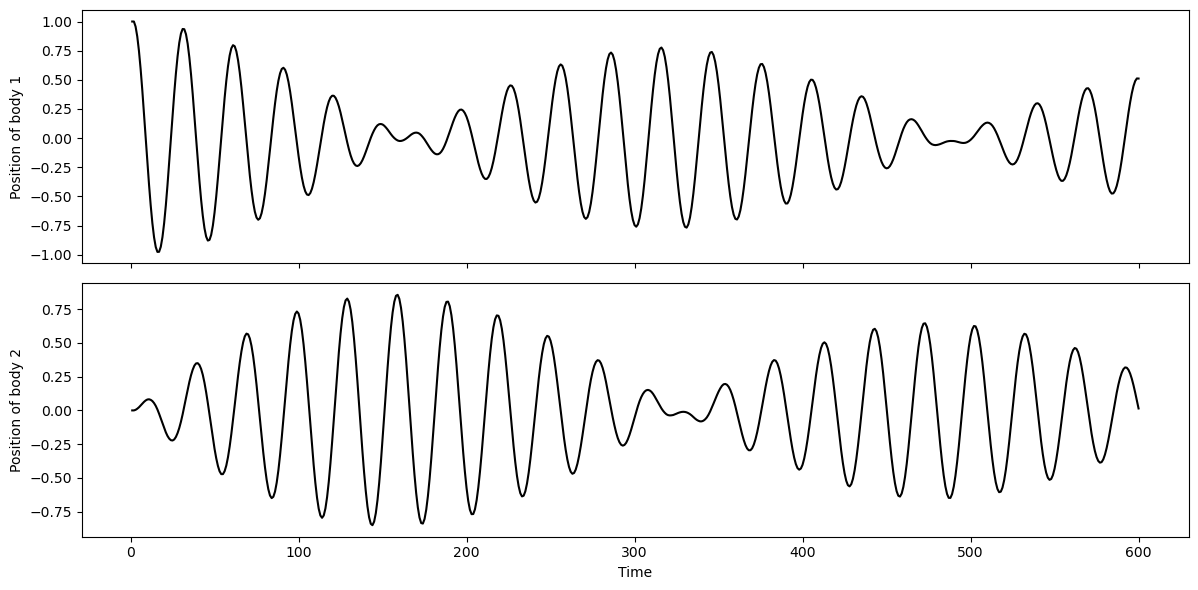

In [4]:
rng = np.random.default_rng(153)
n_total = 600
sigma = 0.0005
y = simulate(A1, A2, np.array([1, 0]), n_total, sigma, rng)
time = np.arange(1, n_total + 1)

fig, ax = plt.subplots(2, 1, figsize = (12, 6), sharex = True)
ax[0].plot(time, y[:, 0], color = 'black')
ax[0].set_ylabel('Position of body 1')
ax[1].plot(time, y[:, 1], color = 'black')
ax[1].set_ylabel('Position of body 2')
ax[1].set_xlabel('Time')
plt.tight_layout()
plt.show()

Body 1 starts oscillating with a period of about 30 time points (a single body of mass $m$ attached to a spring with spring constant $\kappa$ oscillates with period $2 \pi \sqrt{m/\kappa} = 3.14$ seconds, which is 31.4 time points). Because of the spring between the two bodies, body 2 also slowly starts oscillating, and the oscillations of body 1 become smaller. Around time 160, body 1 is almost at rest and body 2 is doing all the moving. After that, the motion goes back to body 1, and so on. The motion is thus passed back and forth between the two bodies (and it slowly dies out because of friction).

## Fitting the VAR(2) model

Suppose now that we only have the data for the first $n = 150$ time points. We want to learn the model from this data, and then predict the positions of the two bodies at the future time points $151, \dots, 600$.

In [5]:
n = 150
ytrain = y[:n]

Each of the two equations of the VAR(2) model is a linear regression. In the first equation, the response is $y_t(1)$ and the covariates are $y_{t-1}(1), y_{t-1}(2), y_{t-2}(1), y_{t-2}(2)$. The second equation has the response $y_t(2)$ and the same covariates. So the model can be fit by least squares, one equation at a time (we also include an intercept in each regression, as in AR models; here the true intercepts are zero).

In [6]:
#The covariates are 1, y_{t-1}(1), y_{t-1}(2), y_{t-2}(1), y_{t-2}(2) for t = 3, ..., n
Z = np.column_stack([np.ones(n - 2), ytrain[1:-1, 0], ytrain[1:-1, 1], ytrain[:-2, 0], ytrain[:-2, 1]])
names = ['intercept', 'y_{t-1}(1)', 'y_{t-1}(2)', 'y_{t-2}(1)', 'y_{t-2}(2)']

#Equation for body 1:
eq1 = sm.OLS(ytrain[2:, 0], Z).fit()
true1 = [0, A1[0, 0], A1[0, 1], A2[0, 0], A2[0, 1]]
print("Equation for body 1:")
print(pd.DataFrame({'true value': true1, 'estimate': eq1.params, 'std. error': eq1.bse}, index = names).round(5))

#Equation for body 2:
eq2 = sm.OLS(ytrain[2:, 1], Z).fit()
true2 = [0, A1[1, 0], A1[1, 1], A2[1, 0], A2[1, 1]]
print("Equation for body 2:")
print(pd.DataFrame({'true value': true2, 'estimate': eq2.params, 'std. error': eq2.bse}, index = names).round(5))

Equation for body 1:
            true value  estimate  std. error
intercept        0.000   0.00004     0.00003
y_{t-1}(1)       1.954   1.95462     0.00044
y_{t-1}(2)       0.004   0.00363     0.00053
y_{t-2}(1)      -0.998  -0.99852     0.00044
y_{t-2}(2)       0.000   0.00055     0.00052
Equation for body 2:
            true value  estimate  std. error
intercept        0.000  -0.00005     0.00005
y_{t-1}(1)       0.004   0.00337     0.00062
y_{t-1}(2)       1.954   1.95413     0.00073
y_{t-2}(1)       0.000   0.00062     0.00061
y_{t-2}(2)      -0.998  -0.99815     0.00073


The estimates are close to the true values. In particular, the data tells us that the two bodies are connected: the estimated coefficient of $y_{t-1}(2)$ in the equation for body 1, and that of $y_{t-1}(1)$ in the equation for body 2, are both close to the true value $b = 0.004$.

In `statsmodels`, VAR models are fit by the function `VAR`. It gives the same estimates as the two regressions above.

In [7]:
var2 = VAR(ytrain).fit(2)
c_hat = var2.intercept
A1_hat = var2.coefs[0]
A2_hat = var2.coefs[1]
print("Estimate of the intercept:", np.round(c_hat, 6))
print("Estimate of A1:")
print(np.round(A1_hat, 6))
print("Estimate of A2:")
print(np.round(A2_hat, 6))
print("Estimate of the standard deviation of the errors of the two equations:", np.round(np.sqrt(np.diag(var2.sigma_u)), 6))

Estimate of the intercept: [ 0.000039 -0.000048]
Estimate of A1:
[[1.95462  0.003631]
 [0.003367 1.954128]]
Estimate of A2:
[[-0.998518  0.000553]
 [ 0.000619 -0.998149]]
Estimate of the standard deviation of the errors of the two equations: [0.000404 0.000563]


The general VAR($p$) model has $p$ past values of all the series on the right hand side of each equation. As in the case of AR models, the order $p$ can be chosen by AIC or BIC.

In [8]:
print(VAR(ytrain).select_order(maxlags = 6).summary())

 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0      -3.062      -3.021     0.04677      -3.046
1      -10.65      -10.52   2.376e-05      -10.60
2     -30.53*     -30.32*  5.512e-14*     -30.45*
3      -30.48      -30.19   5.800e-14      -30.36
4      -30.47      -30.10   5.852e-14      -30.32
5      -30.42      -29.97   6.140e-14      -30.24
6      -30.39      -29.85   6.335e-14      -30.17
-------------------------------------------------


Both AIC and BIC select $p = 2$, which is the order dictated by the physics.

## Predicting each body separately

What happens if we ignore the connection between the two bodies, and model each of the two series separately? From Lecture 16, the natural model for the position of a single body attached to a spring is the AR(2) model. So let us fit the AR(2) model separately to the two series.

In [9]:
ar_body1 = AutoReg(ytrain[:, 0], lags = 2).fit()
ar_body2 = AutoReg(ytrain[:, 1], lags = 2).fit()
print("AR(2) for body 1: intercept, phi_1, phi_2 =", np.round(ar_body1.params, 4))
print("AR(2) for body 2: intercept, phi_1, phi_2 =", np.round(ar_body2.params, 4))

AR(2) for body 1: intercept, phi_1, phi_2 = [-0.0001  1.9427 -0.9867]
AR(2) for body 2: intercept, phi_1, phi_2 = [-0.      1.9694 -1.0139]


Predictions for the future time points are obtained by the usual recursion (as in Lecture 16).

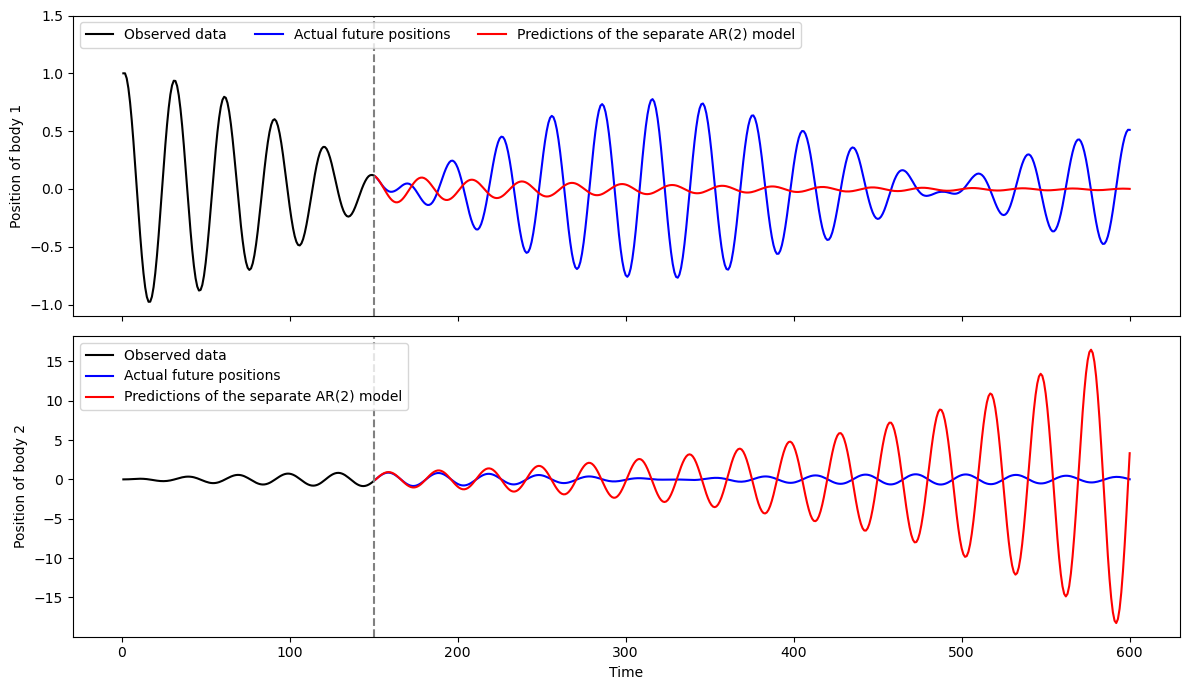

In [10]:
pred_ar = np.zeros((n_total, 2))
pred_ar[:n] = ytrain
for t in range(n, n_total):
    pred_ar[t, 0] = ar_body1.params[0] + ar_body1.params[1] * pred_ar[t-1, 0] + ar_body1.params[2] * pred_ar[t-2, 0]
    pred_ar[t, 1] = ar_body2.params[0] + ar_body2.params[1] * pred_ar[t-1, 1] + ar_body2.params[2] * pred_ar[t-2, 1]

fig, ax = plt.subplots(2, 1, figsize = (12, 7), sharex = True)
for j in range(2):
    ax[j].plot(time[:n], ytrain[:, j], color = 'black', label = 'Observed data')
    ax[j].plot(time[n:], y[n:, j], color = 'blue', label = 'Actual future positions')
    ax[j].plot(time[n:], pred_ar[n:, j], color = 'red', label = 'Predictions of the separate AR(2) model')
    ax[j].axvline(n, color = 'gray', linestyle = '--')
    ax[j].set_ylabel('Position of body ' + str(j + 1))
ax[0].set_ylim(-1.1, 1.5)
ax[0].legend(loc = 'upper left', ncol = 3)
ax[1].legend(loc = 'upper left')
ax[1].set_xlabel('Time')
plt.tight_layout()
plt.show()

These predictions make no sense:

1. For body 1, the predictions say that the body will come to rest and stay there. In reality, body 1 starts moving again (because it is pulled by body 2 which is oscillating), and by time 300 it is again making large oscillations.
2. For body 2, the predictions say that the oscillations will keep growing forever (note the scale of the vertical axis in the second plot). This is physically impossible, as there is nothing which can supply so much energy to the system. In reality, the positions of body 2 always stay between $-1$ and $1$.

The reason is that each AR(2) model only knows the past of its own series. In the observed data, the oscillations of body 2 are growing, and the AR(2) model for body 2 simply continues this growth. Similarly, the oscillations of body 1 are dying out in the observed data, and the AR(2) model for body 1 continues this. Recall from Lecture 19 that an AR model is stable when all the roots of its AR polynomial have modulus larger than 1. Here are the moduli of the roots for the two fitted AR(2) models.

In [11]:
print("Body 1: moduli of the roots of the AR polynomial =", np.round(np.abs(ar_body1.roots), 4))
print("Body 2: moduli of the roots of the AR polynomial =", np.round(np.abs(ar_body2.roots), 4))

Body 1: moduli of the roots of the AR polynomial = [1.0067 1.0067]
Body 2: moduli of the roots of the AR polynomial = [0.9931 0.9931]


The fitted AR(2) model for body 2 is not stable (the moduli of its roots are smaller than 1), which is why its predictions blow up.

## Predicting with the VAR(2) model

Predictions from the fitted VAR(2) model are obtained by the same kind of recursion, now with vectors and matrices:
\begin{align*}
   \hat{y}_{t} = \hat{c} + \hat{A}_1 \hat{y}_{t-1} + \hat{A}_2 \hat{y}_{t-2} ~~~ \text{ for } t = n+1, n+2, \dots
\end{align*}
where $\hat{y}_t$ is taken to be the observed $y_t$ for $t \leq n$.

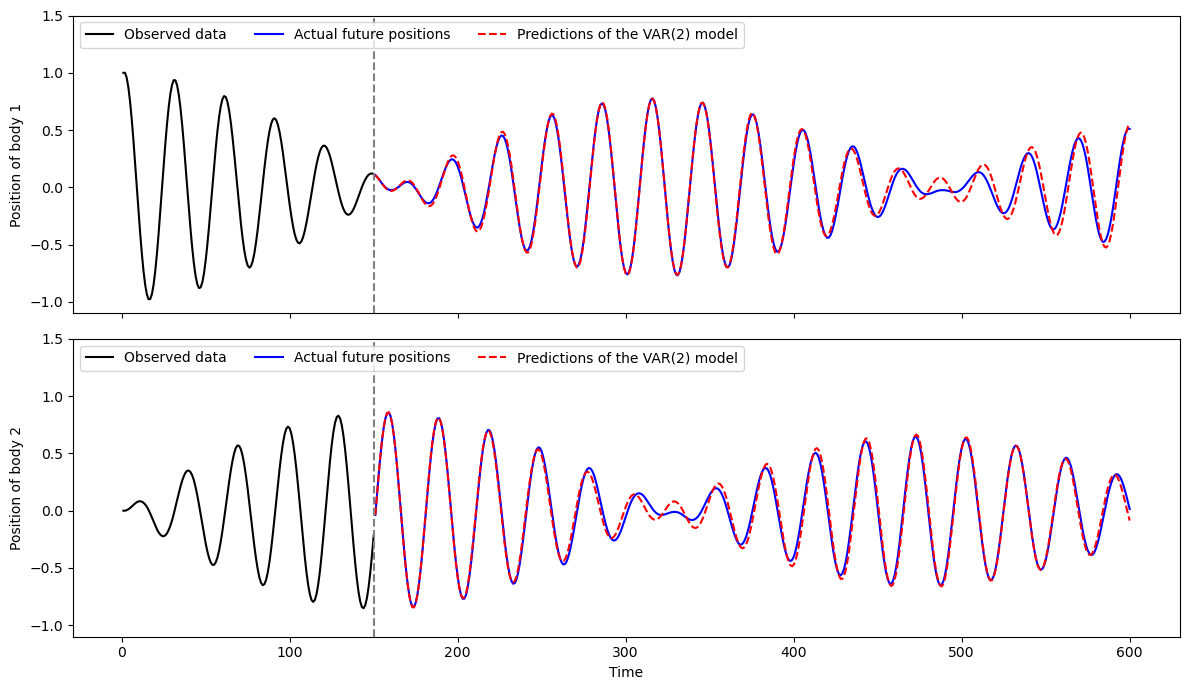

In [12]:
pred_var = np.zeros((n_total, 2))
pred_var[:n] = ytrain
for t in range(n, n_total):
    pred_var[t] = c_hat + A1_hat @ pred_var[t-1] + A2_hat @ pred_var[t-2]
#the same predictions are given by var2.forecast(ytrain[-2:], steps = n_total - n)

fig, ax = plt.subplots(2, 1, figsize = (12, 7), sharex = True)
for j in range(2):
    ax[j].plot(time[:n], ytrain[:, j], color = 'black', label = 'Observed data')
    ax[j].plot(time[n:], y[n:, j], color = 'blue', label = 'Actual future positions')
    ax[j].plot(time[n:], pred_var[n:, j], color = 'red', linestyle = '--', label = 'Predictions of the VAR(2) model')
    ax[j].axvline(n, color = 'gray', linestyle = '--')
    ax[j].set_ylabel('Position of body ' + str(j + 1))
    ax[j].set_ylim(-1.1, 1.5)
    ax[j].legend(loc = 'upper left', ncol = 3)
ax[1].set_xlabel('Time')
plt.tight_layout()
plt.show()

The VAR(2) model predicts the future positions of both the bodies very well for all the 450 future time points. It correctly predicts that body 1 starts moving again, and that the motion keeps going back and forth between the two bodies. Here are the root mean squared errors (RMSE) of the two sets of predictions.

In [13]:
rmse_ar = np.sqrt(np.mean((pred_ar[n:] - y[n:]) ** 2, axis = 0))
rmse_var = np.sqrt(np.mean((pred_var[n:] - y[n:]) ** 2, axis = 0))
print(pd.DataFrame({'separate AR(2) models': rmse_ar, 'VAR(2) model': rmse_var}, index = ['RMSE for body 1', 'RMSE for body 2']).round(3))

                 separate AR(2) models  VAR(2) model
RMSE for body 1                  0.365         0.057
RMSE for body 2                  5.670         0.047


Can the separate models be rescued by increasing their order? Below we fit the AR($p$) model separately to each series for $p = 2, 4, 8$ and $17$. The last value $p = 17$ is the order that is selected by AIC (and also by BIC) for each of the two series when orders up to 20 are allowed.

In [14]:
for j in range(2):
    sel = ar_select_order(ytrain[:, j], maxlag = 20, ic = 'aic')
    print("Order selected by AIC for the AR model for body", j + 1, "=", max(sel.ar_lags))

for p in [2, 4, 8, 17]:
    pred_p = np.column_stack([AutoReg(ytrain[:, j], lags = p).fit().forecast(n_total - n) for j in range(2)])
    rmse_p = np.sqrt(np.mean((pred_p - y[n:]) ** 2, axis = 0))
    print(f"Separate AR({p}) models: RMSE for bodies 1 and 2 = {np.round(rmse_p, 3)}, largest |prediction| = {np.round(np.max(np.abs(pred_p), axis = 0), 2)}")
print(f"VAR(2) model: RMSE for bodies 1 and 2 = {np.round(rmse_var, 3)}, largest |prediction| = {np.round(np.max(np.abs(pred_var[n:]), axis = 0), 2)}")
print("Largest actual |position| of bodies 1 and 2 over the future time points =", np.round(np.max(np.abs(y[n:]), axis = 0), 2))

Order selected by AIC for the AR model for body 1 = 17
Order selected by AIC for the AR model for body 2 = 17
Separate AR(2) models: RMSE for bodies 1 and 2 = [0.365 5.67 ], largest |prediction| = [ 0.12 18.26]
Separate AR(4) models: RMSE for bodies 1 and 2 = [0.366 4.724], largest |prediction| = [ 0.13 14.66]
Separate AR(8) models: RMSE for bodies 1 and 2 = [0.338 3.188], largest |prediction| = [0.11 8.86]
Separate AR(17) models: RMSE for bodies 1 and 2 = [0.22  0.567], largest |prediction| = [0.62 0.89]
VAR(2) model: RMSE for bodies 1 and 2 = [0.057 0.047], largest |prediction| = [0.77 0.86]
Largest actual |position| of bodies 1 and 2 over the future time points = [0.78 0.86]


With $p = 4$ and $p = 8$, the predictions for body 1 still die out and those for body 2 still blow up. With $p = 17$, the predictions no longer blow up, but they are still much worse than those of the VAR(2) model: their RMSEs are about 4 times (body 1) and 12 times (body 2) larger. Note that each AR(17) model has 18 coefficients, while each equation of the VAR(2) model has only 5 coefficients.

## Five bodies in a row

The same physics works for any number of bodies and for any pattern of connections between them. In general, the matrix $A_1$ has a nonzero entry in position $(i, j)$ (for $i \neq j$) exactly when body $i$ and body $j$ are connected by a spring, and the matrix $A_2$ is diagonal. As an example, consider $k = 5$ bodies (each of mass $m$) arranged in a row between two walls, with each body connected to its two neighbours (or to the wall) by identical springs with spring constant $\kappa$:

```
wall |--/\/\--[1]--/\/\--[2]--/\/\--[3]--/\/\--[4]--/\/\--[5]--/\/\--| wall
```

Each body is now attached to two springs, so the diagonal entries of $A_1$ are $2 - 2a - g$. The entries next to the diagonal are equal to $a$, and all the other entries are zero (for example, the $(1, 3)$ entry is zero because bodies 1 and 3 are not connected).

In [15]:
k = 5
A1_chain = np.zeros((k, k))
for i in range(k):
    A1_chain[i, i] = 2 - 2 * a - g
    if i > 0:
        A1_chain[i, i-1] = a
    if i < k - 1:
        A1_chain[i, i+1] = a
A2_chain = -(1 - g) * np.eye(k)
print(A1_chain)

[[1.918 0.04  0.    0.    0.   ]
 [0.04  1.918 0.04  0.    0.   ]
 [0.    0.04  1.918 0.04  0.   ]
 [0.    0.    0.04  1.918 0.04 ]
 [0.    0.    0.    0.04  1.918]]


As before, we pull body 1 by one unit, release it, and record the positions of all the five bodies at 450 time points.

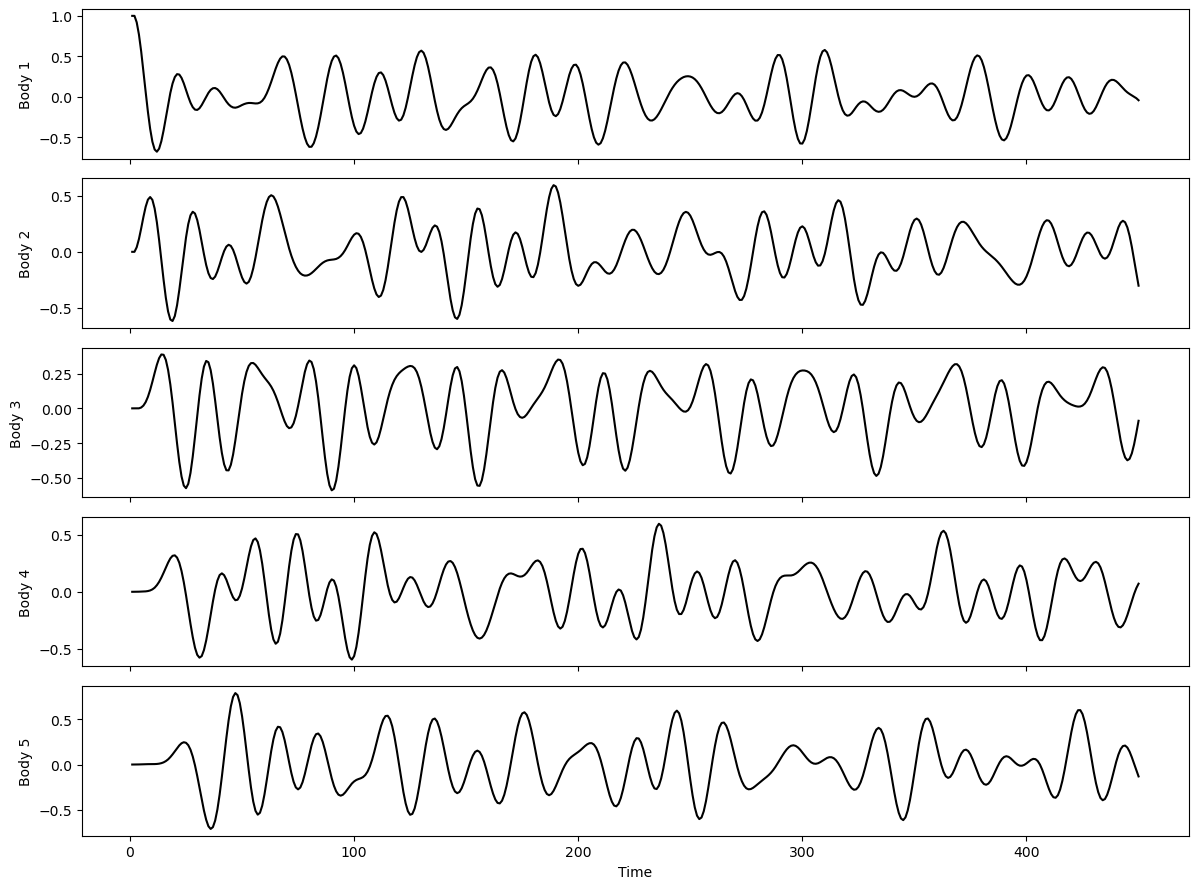

In [16]:
rng = np.random.default_rng(248)
n_total_chain = 450
y_chain = simulate(A1_chain, A2_chain, np.array([1, 0, 0, 0, 0]), n_total_chain, sigma, rng)
time_chain = np.arange(1, n_total_chain + 1)

fig, ax = plt.subplots(k, 1, figsize = (12, 9), sharex = True)
for j in range(k):
    ax[j].plot(time_chain, y_chain[:, j], color = 'black')
    ax[j].set_ylabel('Body ' + str(j + 1))
ax[k-1].set_xlabel('Time')
plt.tight_layout()
plt.show()

The motion now looks quite complicated. The disturbance travels along the row: body 2 starts moving a little after body 1, then body 3, and so on (body 5 hardly moves during the first 10 time points). It then gets reflected at the wall and travels back.

We again fit the VAR(2) model to the first $n = 150$ observations. Each of the five equations now has 11 coefficients (the intercept, and two past values of each of the five series).

In [17]:
var2_chain = VAR(y_chain[:n]).fit(2)
print("Estimate of A1:")
print(np.round(var2_chain.coefs[0], 3))
print("Estimate of A2:")
print(np.round(var2_chain.coefs[1], 3))

Estimate of A1:
[[ 1.918  0.04   0.     0.001 -0.   ]
 [ 0.039  1.918  0.04   0.    -0.   ]
 [-0.     0.04   1.917  0.041  0.001]
 [ 0.     0.001  0.041  1.919  0.041]
 [ 0.     0.001  0.002  0.042  1.919]]
Estimate of A2:
[[-0.998 -0.     0.    -0.001  0.   ]
 [ 0.001 -0.998  0.    -0.     0.   ]
 [-0.    -0.    -0.997 -0.    -0.001]
 [-0.    -0.001 -0.001 -0.999 -0.001]
 [-0.    -0.001 -0.001 -0.002 -0.999]]


The estimates are very close to the true matrices. Note that the VAR model was not told which bodies are connected to which: the pattern of connections can be read off from the estimate of $A_1$ (the entries which are not next to the diagonal are all estimated to be nearly zero).

Here are the predictions for the future time points $151, \dots, 450$ from the VAR(2) model, and from AR(2) models fitted separately to each of the five series.

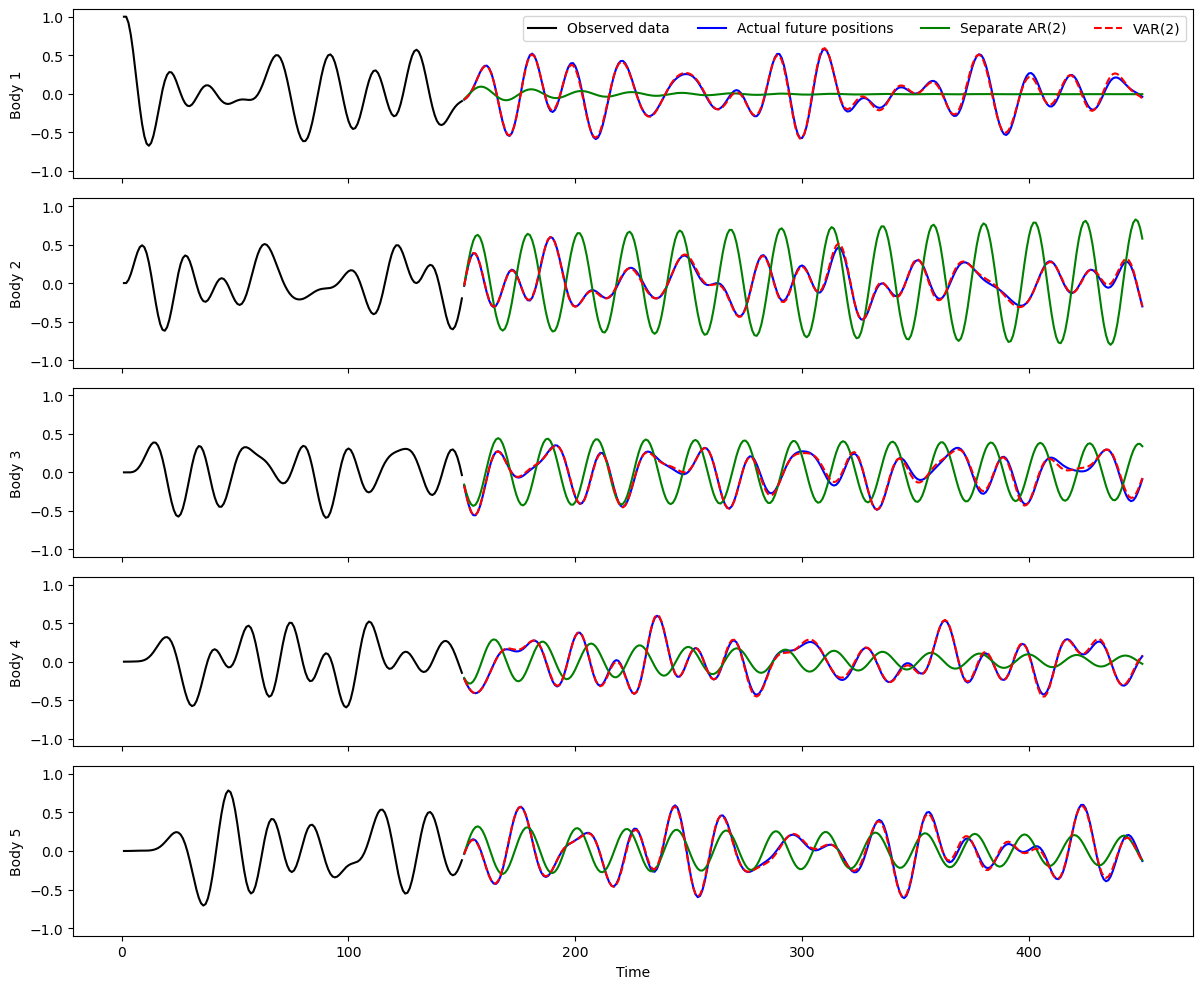

                 separate AR(2) models  VAR(2) model
RMSE for body 1                  0.250         0.022
RMSE for body 2                  0.552         0.018
RMSE for body 3                  0.295         0.022
RMSE for body 4                  0.253         0.015
RMSE for body 5                  0.215         0.020


In [18]:
pred_var_chain = var2_chain.forecast(y_chain[n-2:n], steps = n_total_chain - n)
pred_ar_chain = np.column_stack([AutoReg(y_chain[:n, j], lags = 2).fit().forecast(n_total_chain - n) for j in range(k)])

fig, ax = plt.subplots(k, 1, figsize = (12, 10), sharex = True)
for j in range(k):
    ax[j].plot(time_chain[:n], y_chain[:n, j], color = 'black', label = 'Observed data')
    ax[j].plot(time_chain[n:], y_chain[n:, j], color = 'blue', label = 'Actual future positions')
    ax[j].plot(time_chain[n:], pred_ar_chain[:, j], color = 'green', label = 'Separate AR(2)')
    ax[j].plot(time_chain[n:], pred_var_chain[:, j], color = 'red', linestyle = '--', label = 'VAR(2)')
    ax[j].set_ylabel('Body ' + str(j + 1))
    ax[j].set_ylim(-1.1, 1.1)
ax[0].legend(loc = 'upper right', ncol = 4)
ax[k-1].set_xlabel('Time')
plt.tight_layout()
plt.show()

rmse_ar_chain = np.sqrt(np.mean((pred_ar_chain - y_chain[n:]) ** 2, axis = 0))
rmse_var_chain = np.sqrt(np.mean((pred_var_chain - y_chain[n:]) ** 2, axis = 0))
print(pd.DataFrame({'separate AR(2) models': rmse_ar_chain, 'VAR(2) model': rmse_var_chain}, index = ['RMSE for body ' + str(j + 1) for j in range(k)]).round(3))

The predictions of the VAR(2) model (red) are almost indistinguishable from the actual future positions (blue), for all the five bodies. The predictions of the separate AR(2) models (green) are single sinusoids which have nothing to do with the actual motion.

## Granger causality

A basic question about several time series is: which series help in predicting which? We say that series $j$ **Granger-causes** series $i$ if the past values of series $j$ help in predicting $y_t(i)$, over and above the past values of the other series (including series $i$ itself). In the VAR($p$) model, the past values of series $j$ enter the equation for $y_t(i)$ through the $(i, j)$ entries of the matrices $A_1, \dots, A_p$. So series $j$ Granger-causes series $i$ when these entries are not all zero.

For connected bodies, the $(i, j)$ entry of $A_1$ equals $\Delta^2 \kappa_{ij}/m_i$, where $\kappa_{ij}$ is the spring constant of the spring connecting bodies $i$ and $j$ (this is zero if they are not connected), and $m_i$ is the mass of body $i$. So in the row of five bodies above, each body Granger-causes its neighbours and no other body. Also note that the $(i, j)$ entry is close to zero when body $i$ is very heavy: a light body cannot move a heavy body.

### A heavy body and two light bodies

To illustrate Granger causality, we use the following system of three bodies. Body 1 is very heavy. It is attached to a wall by a spring, and it gets hit by random disturbances (as in Lecture 16, think of kids randomly throwing stones at it). Bodies 2 and 3 are light. Each of them is attached to body 1 by its own spring (body 2 by a stiff spring and body 3 by a soft spring). Bodies 2 and 3 are **not** connected to each other.

```
                                  /---/\/\/\/\---[ body 2 ]     (stiff spring)
wall |---/\/\/\/\---[   body 1   ]
                    [  (heavy)   ]
                                  \---/\/\/\/\---[ body 3 ]     (soft spring)
```

Because body 1 is very heavy, it is not affected by bodies 2 and 3. So the equations are
\begin{align*}
   y_t(1) &= (2 - a_1 - g_1) y_{t-1}(1) - (1 - g_1) y_{t-2}(1) + \epsilon_t(1) \\
   y_t(2) &= b_2 y_{t-1}(1) + (2 - b_2 - g_2) y_{t-1}(2) - (1 - g_2) y_{t-2}(2) + \epsilon_t(2) \\
   y_t(3) &= b_3 y_{t-1}(1) + (2 - b_3 - g_3) y_{t-1}(3) - (1 - g_3) y_{t-2}(3) + \epsilon_t(3).
\end{align*}
Here $a_1$ comes from the spring between body 1 and the wall, $b_2$ and $b_3$ come from the springs which attach bodies 2 and 3 to body 1, and $g_1, g_2, g_3$ come from friction (see the lecture notes).

In [19]:
a1, g1 = 0.04, 0.02    #heavy body 1: spring (to the wall) and friction
b2, g2 = 0.5, 0.3      #light body 2: spring (to body 1) and friction
b3, g3 = 0.05, 0.1     #light body 3: spring (to body 1) and friction

A1_gc = np.array([[2 - a1 - g1, 0, 0], [b2, 2 - b2 - g2, 0], [b3, 0, 2 - b3 - g3]])
A2_gc = np.array([[-(1 - g1), 0, 0], [0, -(1 - g2), 0], [0, 0, -(1 - g3)]])
print("A1 =")
print(A1_gc)
print("A2 =")
print(A2_gc)

A1 =
[[1.94 0.   0.  ]
 [0.5  1.2  0.  ]
 [0.05 0.   1.85]]
A2 =
[[-0.98  0.    0.  ]
 [ 0.   -0.7   0.  ]
 [ 0.    0.   -0.9 ]]


We simulate $2000$ observations from this model, starting with all the three bodies at rest. The random disturbances to body 1 have standard deviation 1, and those to bodies 2 and 3 have the much smaller standard deviation $0.05$. Here are the positions of the three bodies at all the 2000 time points.

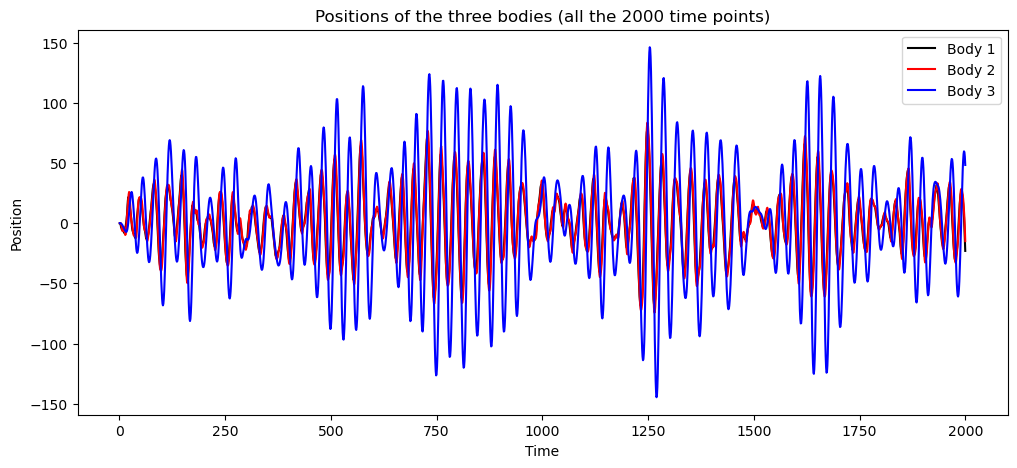

In [20]:
rng = np.random.default_rng(22)
n_gc = 2000
sigma_gc = np.array([1, 0.05, 0.05])
y_gc = simulate(A1_gc, A2_gc, np.array([0, 0, 0]), n_gc, sigma_gc, rng)

plt.figure(figsize = (12, 5))
plt.plot(np.arange(1, n_gc + 1), y_gc[:, 0], color = 'black', label = 'Body 1')
plt.plot(np.arange(1, n_gc + 1), y_gc[:, 1], color = 'red', label = 'Body 2')
plt.plot(np.arange(1, n_gc + 1), y_gc[:, 2], color = 'blue', label = 'Body 3')
plt.xlabel('Time')
plt.ylabel('Position')
plt.title('Positions of the three bodies (all the 2000 time points)')
plt.legend()
plt.show()

Body 1 oscillates irregularly (just like the simulations from the AR(2) model in Lecture 16): the size of its oscillations keeps changing because of the random disturbances. Bodies 2 and 3 are driven by body 1. On this scale, body 2 cannot be distinguished from body 1 (the red curve covers the black curve), while body 3 makes larger oscillations. Here is a closer look at 300 of the time points.

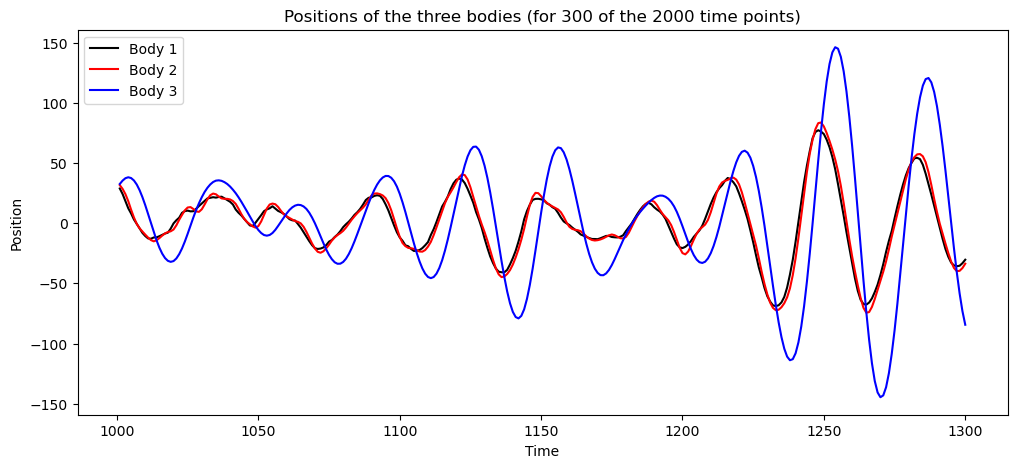

In [21]:
plt.figure(figsize = (12, 5))
plt.plot(np.arange(1001, 1301), y_gc[1000:1300, 0], color = 'black', label = 'Body 1')
plt.plot(np.arange(1001, 1301), y_gc[1000:1300, 1], color = 'red', label = 'Body 2')
plt.plot(np.arange(1001, 1301), y_gc[1000:1300, 2], color = 'blue', label = 'Body 3')
plt.xlabel('Time')
plt.ylabel('Position')
plt.title('Positions of the three bodies (for 300 of the 2000 time points)')
plt.legend()
plt.show()

Body 2 follows body 1 closely with a small delay, and body 3 follows with a longer delay. The positions of bodies 1 and 2 are very close to each other, but they are not the same. This can be seen by plotting these two bodies over a short time interval.

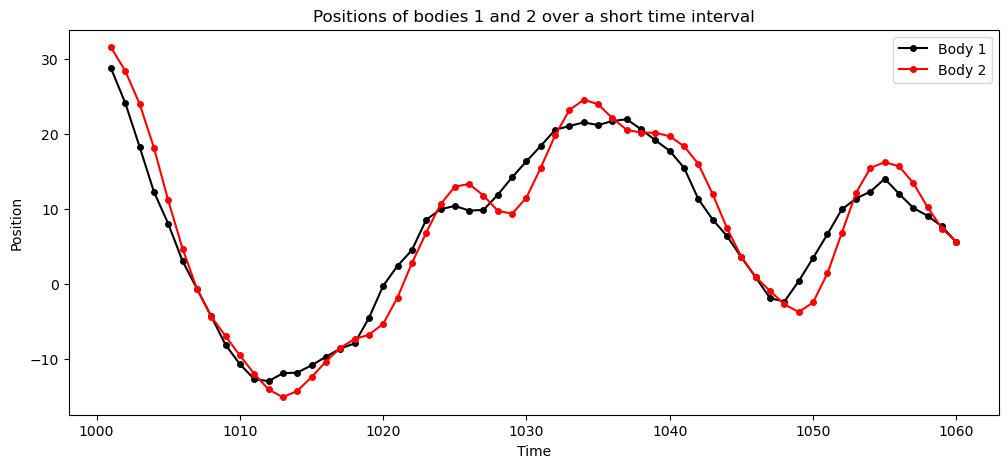

In [22]:
#bodies 1 and 2 over a short time interval (60 time points)
t1, t2 = 1001, 1060    #first and last time points of the interval (try also 1221 and 1280, where the oscillations are larger)
plt.figure(figsize = (12, 5))
plt.plot(np.arange(t1, t2 + 1), y_gc[t1 - 1 : t2, 0], color = 'black', marker = 'o', markersize = 4, label = 'Body 1')
plt.plot(np.arange(t1, t2 + 1), y_gc[t1 - 1 : t2, 1], color = 'red', marker = 'o', markersize = 4, label = 'Body 2')
plt.xlabel('Time')
plt.ylabel('Position')
plt.title('Positions of bodies 1 and 2 over a short time interval')
plt.legend()
plt.show()

Body 1 turns around first, and body 2 follows about one time point later (for example, body 1 reaches a low point at time 1048, and body 2 at time 1049). The gap between the two bodies is small compared to the size of the oscillations: over all the 2000 time points, the positions of these two bodies range from about $-80$ to $80$, while the gap between them is typically about 4. We shall see below that this small gap is important.

### Bodies 1 and 2

We first look at bodies 1 and 2 only. Here is the VAR(2) model fitted to these two series (using the first 1000 observations).

In [23]:
n_fit = 1000
var2_gc = VAR(y_gc[:n_fit, :2]).fit(2)
print("Estimate of A1:")
print(np.round(var2_gc.coefs[0], 3))
print("Estimate of A2:")
print(np.round(var2_gc.coefs[1], 3))

Estimate of A1:
[[1.933 0.023]
 [0.499 1.202]]
Estimate of A2:
[[-0.994 -0.003]
 [-0.002 -0.7  ]]


In the second row of the estimates (this is the equation for body 2), the coefficient of $y_{t-1}(1)$ is close to its true value $0.5$. In the first row (the equation for body 1), the coefficients of the past values of body 2 are small (their true values are zero). But estimated coefficients are never exactly zero. So how do we judge whether the past of body 2 helps in predicting body 1?

### Comparing predictions

Because Granger causality is about prediction, the most direct way is to compare the accuracy of predictions with and without the past values of the other series. This is done by the function `prediction_rmse` below. Its inputs are the data, the series which is to be predicted (`target`), the list of the series whose past values are used for the prediction (`predictors`), the number $p$ of past values, and the number `n_fit` of time points which are used for fitting. It does the following:

1. It regresses $y_t(i)$ (where $i$ is the target series) on $1$ and on $y_{t-1}(j), \dots, y_{t-p}(j)$ for every series $j$ in `predictors`. This regression is fitted by least squares using only the first `n_fit` time points.
2. It uses the fitted regression to predict $y_t(i)$ at each of the remaining time points $t$. Each prediction is calculated from the actual observations at the $p$ previous time points $t-1, \dots, t-p$ (the regression is not fitted again).
3. It returns the root mean squared error (RMSE) of these predictions, i.e., the square root of the average of the squared prediction errors.

For example, if the target is body 2 and the predictors are bodies 1 and 2, then the regression in step 1 is the equation for body 2 in the VAR($p$) model for bodies 1 and 2. If the predictor is body 2 alone, then it is the AR($p$) model for body 2. By default, $p = 2$ and `n_fit` is 1000, so the regressions are fitted on the first 1000 time points, and the predictions are for the remaining 1000 time points.

Note that the prediction errors are calculated at time points which were not used for fitting the regression. This matters. The usual residual sum of squares of a regression (which is calculated at the time points used for fitting) always becomes smaller when more covariates are added, so it cannot tell us whether the additional covariates are useful. The prediction error at new time points can go up or down, and so the RMSEs with and without the additional series can be compared directly.

In [24]:
def lagged(data, p):
    #the row of the output corresponding to time t consists of 1, data[t-1], ..., data[t-p]
    n = data.shape[0]
    return np.column_stack([np.ones(n - p)] + [data[p - j : n - j] for j in range(1, p + 1)])

def prediction_rmse(data, target, predictors, p = 2, n_fit = 1000):
    response = data[p:, target]                                   #the target series from time p+1 onwards
    Z = lagged(data[:, predictors], p)                            #the covariates: 1 and the p past values of the predictor series
    reg = sm.OLS(response[:n_fit - p], Z[:n_fit - p]).fit()       #least squares using the first n_fit time points
    errors = response[n_fit - p:] - reg.predict(Z[n_fit - p:])    #prediction errors for the remaining time points
    return np.sqrt(np.mean(errors ** 2))

Here are the results for bodies 1 and 2. In Python, bodies 1, 2, 3 correspond to the columns 0, 1, 2 of the data. So, for example, `prediction_rmse(y_gc, 1, [0, 1])` is the RMSE for predicting body 2 using the past of bodies 1 and 2.

In [25]:
print(f"RMSE for predicting body 1 using the past of body 1 alone:    {prediction_rmse(y_gc, 0, [0]):.3f}")
print(f"RMSE for predicting body 1 using the past of bodies 1 and 2:  {prediction_rmse(y_gc, 0, [0, 1]):.3f}")
print(f"RMSE for predicting body 2 using the past of body 2 alone:    {prediction_rmse(y_gc, 1, [1]):.3f}")
print(f"RMSE for predicting body 2 using the past of bodies 1 and 2:  {prediction_rmse(y_gc, 1, [0, 1]):.3f}")

RMSE for predicting body 1 using the past of body 1 alone:    1.003
RMSE for predicting body 1 using the past of bodies 1 and 2:  1.003
RMSE for predicting body 2 using the past of body 2 alone:    0.967
RMSE for predicting body 2 using the past of bodies 1 and 2:  0.050


The past of body 1 helps enormously in predicting body 2: the prediction error becomes about 20 times smaller (it goes down to $0.05$, which is the standard deviation of the random disturbances to body 2). So body 1 Granger-causes body 2. In the other direction, the past of body 2 does not help at all in predicting body 1: the prediction error stays the same (it is about 1, which is the standard deviation of the random disturbances to body 1). So body 2 does not Granger-cause body 1. This is as expected from the physics: body 1 moves body 2, but body 2 cannot move body 1.

This may look surprising because the positions of bodies 1 and 2 are very close to each other throughout. If body 2 is almost a copy of body 1, why is its own past not enough for predicting it? To see why, note that the equation for body 2 can be written as
\begin{align*}
   y_t(2) - y_{t-1}(2) = 0.5 \left(y_{t-1}(1) - y_{t-1}(2) \right) + 0.7 \left(y_{t-1}(2) - y_{t-2}(2) \right) + \epsilon_t(2).
\end{align*}
So the movement of body 2 is driven by the small gap between the two bodies (this gap is the stretch of the spring between them). When the past of both the bodies is used, this gap is known, and the only unknown is $\epsilon_t(2)$. The past of body 2 alone does not determine the gap accurately, because body 2 follows body 1 with a delay: the most recent random disturbance to body 1 has not yet reached body 2. Note also that both the prediction errors are small compared to the size of the oscillations (the RMSE of $0.967$ is less than 4% of the standard deviation of the positions of body 2, which is about 27).

### Bodies 2 and 3

Now let us bring in body 3. Recall that bodies 2 and 3 are not connected to each other. Suppose first that we only have the data on bodies 2 and 3 (body 1 is not observed).

In [26]:
print(f"RMSE for predicting body 3 using the past of body 3 alone:    {prediction_rmse(y_gc, 2, [2]):.3f}")
print(f"RMSE for predicting body 3 using the past of bodies 2 and 3:  {prediction_rmse(y_gc, 2, [1, 2]):.3f}")
print(f"RMSE for predicting body 2 using the past of body 2 alone:    {prediction_rmse(y_gc, 1, [1]):.3f}")
print(f"RMSE for predicting body 2 using the past of bodies 2 and 3:  {prediction_rmse(y_gc, 1, [1, 2]):.3f}")

RMSE for predicting body 3 using the past of body 3 alone:    0.451
RMSE for predicting body 3 using the past of bodies 2 and 3:  0.109
RMSE for predicting body 2 using the past of body 2 alone:    0.967
RMSE for predicting body 2 using the past of bodies 2 and 3:  0.953


The past of body 2 helps a lot in predicting body 3 (the prediction error becomes about 4 times smaller). So, based on these two series, body 2 Granger-causes body 3, even though there is no connection at all between these two bodies. The explanation is that both bodies are driven by body 1, and body 2 reacts to body 1 faster than body 3 does (it is attached by a stiffer spring). So the past of body 2 tells us what body 1 has been doing recently, and this helps in predicting body 3. In the other direction, the past of body 3 hardly helps in predicting body 2 (the prediction error only goes from $0.967$ to $0.953$), because body 3 reacts to body 1 more slowly than body 2 does.

### All the three bodies

Once body 1 is included, body 2 is of no additional use for predicting body 3:

In [27]:
print(f"RMSE for predicting body 3 using the past of bodies 1 and 3:     {prediction_rmse(y_gc, 2, [0, 2]):.3f}")
print(f"RMSE for predicting body 3 using the past of bodies 1, 2 and 3:  {prediction_rmse(y_gc, 2, [0, 1, 2]):.3f}")

RMSE for predicting body 3 using the past of bodies 1 and 3:     0.051
RMSE for predicting body 3 using the past of bodies 1, 2 and 3:  0.051


Here is the VAR(2) model fitted to all the three series. In the estimate of $A_1$, the $(3, 2)$ and $(2, 3)$ entries are nearly zero: when all the three bodies are included, body 2 does not Granger-cause body 3 (and body 3 does not Granger-cause body 2). The $(2, 1)$ and $(3, 1)$ entries are close to their true values $0.5$ and $0.05$, and the $(1, 2)$ and $(1, 3)$ entries are small (body 1 is not affected by the other two bodies).

In [28]:
var2_gc3 = VAR(y_gc[:n_fit]).fit(2)
print("Estimate of A1:")
print(np.round(var2_gc3.coefs[0], 3))
print("Estimate of A2:")
print(np.round(var2_gc3.coefs[1], 3))

Estimate of A1:
[[ 1.935  0.025 -0.002]
 [ 0.499  1.202  0.   ]
 [ 0.052 -0.002  1.85 ]]
Estimate of A2:
[[-0.998 -0.002  0.002]
 [-0.001 -0.7   -0.   ]
 [-0.002  0.002 -0.9  ]]


### Summary

1. Granger causality has a direction: body 1 Granger-causes body 2, but body 2 does not Granger-cause body 1.
2. Granger causality is a statement about prediction, and it need not mean that one series actually causes the other. Body 2 has no effect whatsoever on body 3, but its past helps in predicting body 3 when body 1 is not observed.
3. Granger causality depends on which series are included in the model.

## A real data example: daily temperatures in Chicago and New York

In all the examples above, the data were simulated from equations that we wrote down ourselves, so we knew what the matrices $A_1$ and $A_2$ should look like. For real data, we usually do not know the equations. We can still fit a VAR model, and then try to learn something about the underlying system from the fitted coefficients (just as we could read off the pattern of connections between the five bodies from the estimate of $A_1$).

The file `DailyTemperature_Chicago_NewYork_July2014_June2015.csv` contains the mean temperature (in degrees Fahrenheit) on each of the 365 days from 1 July 2014 to 30 June 2015 in Chicago (Midway airport) and in New York (Central Park). It also contains the normal temperature for each date in the two cities (this is the long-term average temperature for that date, obtained as the average of the normal minimum and the normal maximum temperatures). The data are from Weather Underground, and were put together by FiveThirtyEight (https://github.com/fivethirtyeight/data/tree/master/us-weather-history).

In [29]:
temps = pd.read_csv("DailyTemperature_Chicago_NewYork_July2014_June2015.csv", parse_dates = ['date'])
print(temps.head())

        date  Chicago  Chicago_normal  NewYork  NewYork_normal
0 2014-07-01       76            75.5       81            75.5
1 2014-07-02       66            75.5       82            75.5
2 2014-07-03       66            75.5       78            75.5
3 2014-07-04       70            75.5       70            76.0
4 2014-07-05       71            75.5       72            76.0


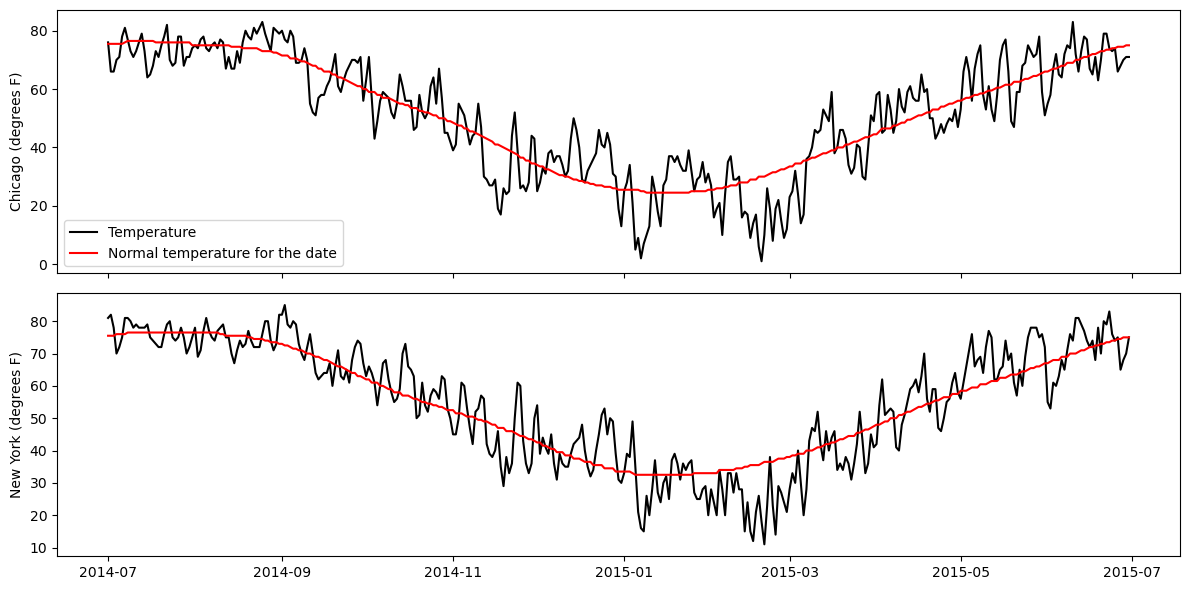

In [30]:
fig, ax = plt.subplots(2, 1, figsize = (12, 6), sharex = True)
ax[0].plot(temps['date'], temps['Chicago'], color = 'black', label = 'Temperature')
ax[0].plot(temps['date'], temps['Chicago_normal'], color = 'red', label = 'Normal temperature for the date')
ax[0].set_ylabel('Chicago (degrees F)')
ax[0].legend()
ax[1].plot(temps['date'], temps['NewYork'], color = 'black')
ax[1].plot(temps['date'], temps['NewYork_normal'], color = 'red')
ax[1].set_ylabel('New York (degrees F)')
plt.tight_layout()
plt.show()

The main feature of both series is the seasonal cycle, which is described by the normal temperatures (red). We are interested in the weather, i.e., in how much warmer or colder than normal each day is. So we take $y_t(1)$ to be the temperature in Chicago on day $t$ minus the normal temperature in Chicago for that date, and $y_t(2)$ to be the temperature in New York on day $t$ minus the normal temperature in New York for that date. For example, $y_t(1) = -10$ means that day $t$ was 10 degrees colder than normal in Chicago. Here are these two series for January and February 2015.

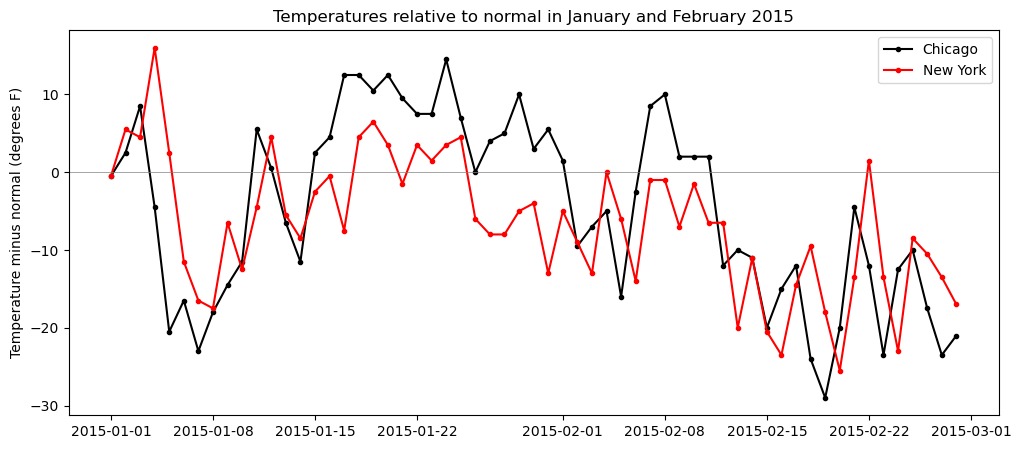

In [31]:
y_weather = np.column_stack([temps['Chicago'] - temps['Chicago_normal'], temps['NewYork'] - temps['NewYork_normal']])

#rows 184 to 242 of the dataset correspond to the dates from 1 January 2015 to 28 February 2015
plt.figure(figsize = (12, 5))
plt.plot(temps['date'].iloc[184:243], y_weather[184:243, 0], color = 'black', marker = 'o', markersize = 3, label = 'Chicago')
plt.plot(temps['date'].iloc[184:243], y_weather[184:243, 1], color = 'red', marker = 'o', markersize = 3, label = 'New York')
plt.axhline(0, color = 'gray', linewidth = 0.5)
plt.ylabel('Temperature minus normal (degrees F)')
plt.title('Temperatures relative to normal in January and February 2015')
plt.legend()
plt.show()

The two series are related: when it is unusually cold in Chicago, it also tends to be unusually cold in New York. We now fit a VAR model to these two series (using all the 365 days). Here we have no physical equations to tell us what the order $p$ should be. We start with the simplest choice $p = 1$, in which today's temperatures are explained by yesterday's temperatures (other values of $p$ are considered below).

In [32]:
var1_weather = VAR(y_weather).fit(1)
print("Estimate of the intercept:", np.round(var1_weather.intercept, 2))
print("Estimate of A1:")
print(np.round(var1_weather.coefs[0], 2))

Estimate of the intercept: [-0.16 -0.01]
Estimate of A1:
[[ 0.79 -0.16]
 [ 0.42  0.42]]


The first row of the estimate of $A_1$ gives the equation for Chicago, and the second row gives the equation for New York. The intercepts are small, so the fitted model says the following (all temperatures are relative to normal):
\begin{align*}
   \text{Chicago today} &\approx 0.79 \times (\text{Chicago yesterday}) - 0.16 \times (\text{New York yesterday}) \\
   \text{New York today} &\approx 0.42 \times (\text{Chicago yesterday}) + 0.42 \times (\text{New York yesterday}).
\end{align*}
The two equations are quite different from each other:

1. For today's temperature in New York, yesterday's temperature in Chicago is as important as yesterday's temperature in New York itself (both coefficients are $0.42$).
2. Today's temperature in Chicago mainly depends on yesterday's temperature in Chicago (the coefficient is $0.79$). The coefficient of yesterday's temperature in New York is much smaller ($-0.16$).

So to predict the temperature in New York tomorrow, we should look at Chicago today. To predict the temperature in Chicago tomorrow, there is not much to be gained by looking at New York today. We did not put any physics into the model, but the fitted model has found a well-known fact about the weather in this part of the world: weather systems (large masses of cold or warm air) travel from west to east. Chicago is about 1150 km to the west of New York, and the air which is over Chicago today is typically over New York about a day later. We can also see this in the plot above. In the cold wave at the beginning of January 2015, the temperature dropped sharply in Chicago on 4 and 5 January, and in New York on 5 and 6 January. The coldest day of the whole year was 19 February 2015 in Chicago, and 20 February 2015 in New York.

In the language of Granger causality, the fitted model suggests that Chicago Granger-causes New York, and that New York does not Granger-cause Chicago. Let us check this in the same way as in the section on Granger causality, by comparing the accuracy of predictions with and without the past of the other city (we use the function `prediction_rmse` from that section). The regressions are fitted using the days in 2014 (these are the first 184 days), and the predictions are evaluated on the days in 2015 (the remaining 181 days). We do this for $p = 1$, and also for $p = 2$ and $p = 4$, which are the orders selected by BIC and AIC respectively. The RMSEs are in degrees Fahrenheit.

In [33]:
sel_weather = VAR(y_weather).select_order(maxlags = 8)
print("Order selected by AIC =", sel_weather.aic, "  Order selected by BIC =", sel_weather.bic)

#Note: Chicago and New York correspond to the columns 0 and 1 of y_weather
for p in [1, 2, 4]:
    print("p =", p)
    print(f"   RMSE for predicting New York using the past of New York alone:         {prediction_rmse(y_weather, 1, [1], p = p, n_fit = 184):.2f}")
    print(f"   RMSE for predicting New York using the past of Chicago and New York:   {prediction_rmse(y_weather, 1, [0, 1], p = p, n_fit = 184):.2f}")
    print(f"   RMSE for predicting Chicago using the past of Chicago alone:           {prediction_rmse(y_weather, 0, [0], p = p, n_fit = 184):.2f}")
    print(f"   RMSE for predicting Chicago using the past of Chicago and New York:    {prediction_rmse(y_weather, 0, [0, 1], p = p, n_fit = 184):.2f}")

Order selected by AIC = 4   Order selected by BIC = 2
p = 1
   RMSE for predicting New York using the past of New York alone:         6.32
   RMSE for predicting New York using the past of Chicago and New York:   5.42
   RMSE for predicting Chicago using the past of Chicago alone:           6.86
   RMSE for predicting Chicago using the past of Chicago and New York:    7.04
p = 2
   RMSE for predicting New York using the past of New York alone:         6.65
   RMSE for predicting New York using the past of Chicago and New York:   5.17
   RMSE for predicting Chicago using the past of Chicago alone:           6.78
   RMSE for predicting Chicago using the past of Chicago and New York:    6.77
p = 4
   RMSE for predicting New York using the past of New York alone:         6.59
   RMSE for predicting New York using the past of Chicago and New York:   5.13
   RMSE for predicting Chicago using the past of Chicago alone:           6.63
   RMSE for predicting Chicago using the past of Chicago an

For each of these values of $p$, the past of Chicago helps in predicting New York: the prediction error becomes smaller by about 14% for $p = 1$, and by about 22% for $p = 2$ and $p = 4$. In the other direction, the past of New York does not help in predicting Chicago: the prediction error does not become smaller (it stays about the same for $p = 2$, and it becomes slightly larger for $p = 1$ and $p = 4$). So Chicago Granger-causes New York, but New York does not Granger-cause Chicago.

Two remarks:

1. The improvement in prediction is much smaller here than in the simulated example in the section on Granger causality (where the prediction error became about 20 times smaller). Real data are rarely as clean as simulated data: for example, weather systems do not always travel from Chicago to New York, and they do not always take exactly one day.
2. Granger causality is a statement about prediction. The weather in Chicago does not cause the weather in New York. Both are caused by the same travelling weather systems, which reach Chicago first. This is just like bodies 2 and 3 in the section on Granger causality: both of them were driven by body 1, and body 2 (which reacted faster) helped in predicting body 3 without having any effect on it.